# Adaptive Multi-Scale Dynamic RFM — Online Retail I

**Research objective:** evaluate whether Customer-Level Adaptive Rolling RFM improves next-month purchase prediction over Static RFM and Fixed Rolling RFM.

**Dataset:** UCI Online Retail I (`Online Retail.xlsx`).

**Important:** all features for snapshot month `t` are calculated using transactions strictly before the first day of month `t+1`. The target is whether the customer purchases during month `t+1`. Window selection and threshold tuning use Validation only; Test is held out for final evaluation.

## Experiments
- E0: Majority-class baseline
- E1: Static/Lifetime RFM
- E2: Fixed Rolling RFM — 90 days
- E3: Best Fixed Rolling Window — selected from 30/60/90/120/180 days on Validation
- E4: Customer-Level Adaptive Rolling RFM — window based on historical inter-purchase interval
- E5: Multi-Scale Dynamic RFM — features from 30/60/90/120/180 days
- E6: Adaptive + Multi-Scale + Temporal features

All primary comparisons use the same Random Forest model. Logistic Regression is included as an additional baseline on Static and Adaptive feature sets.


In [4]:
# 1. Imports & configuration
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

RANDOM_STATE = 42
WINDOWS = [30, 60, 90, 120, 180]

# Temporal split. Dataset ends in Dec-2011; November is a complete target month.
TRAIN_START, TRAIN_END = "2010-12", "2011-06"
VALID_START, VALID_END = "2011-07", "2011-08"
TEST_START, TEST_END = "2011-09", "2011-10"

# Change this to the uploaded Excel/CSV file path.
DATA_PATH = "Online Retail.xlsx"


In [5]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

file_name = next(iter(uploaded))

if file_name.endswith((".xlsx", ".xls")):
    raw = pd.read_excel(io.BytesIO(uploaded[file_name]))
elif file_name.endswith(".csv"):
    raw = pd.read_csv(io.BytesIO(uploaded[file_name]), encoding="latin1")
else:
    raise ValueError("Unsupported file format")

print("Loaded file:", file_name)
print("Shape:", raw.shape)

display(raw.head())

Saving Online Retail.xlsx to Online Retail.xlsx
Loaded file: Online Retail.xlsx
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# 3. Cleaning
def clean_retail(df):
    x = df.copy()
    x.columns = [c.strip() for c in x.columns]

    required = ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate",
                "UnitPrice", "CustomerID"]
    missing = [c for c in required if c not in x.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    x["InvoiceDate"] = pd.to_datetime(x["InvoiceDate"], errors="coerce")
    x["CustomerID"] = pd.to_numeric(x["CustomerID"], errors="coerce")
    x["Quantity"] = pd.to_numeric(x["Quantity"], errors="coerce")
    x["UnitPrice"] = pd.to_numeric(x["UnitPrice"], errors="coerce")

    x = x.dropna(subset=["InvoiceDate", "CustomerID", "Quantity", "UnitPrice"])
    x = x[x["InvoiceNo"].astype(str).str.startswith("C") == False]
    x = x[(x["Quantity"] > 0) & (x["UnitPrice"] > 0)]
    x = x.drop_duplicates()
    x["CustomerID"] = x["CustomerID"].astype(int)
    x["Revenue"] = x["Quantity"] * x["UnitPrice"]
    x["InvoiceDate"] = pd.to_datetime(x["InvoiceDate"])
    return x.sort_values("InvoiceDate").reset_index(drop=True)

data = clean_retail(raw)
print("Clean shape:", data.shape)
print("Customers:", data.CustomerID.nunique())
print("Invoices:", data.InvoiceNo.nunique())
print("Date range:", data.InvoiceDate.min(), "to", data.InvoiceDate.max())
print("Revenue:", data.Revenue.sum())


Clean shape: (392692, 9)
Customers: 4338
Invoices: 18532
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Revenue: 8887208.894000001


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,392692.0,18532.0,576339.0,542.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,392692,3665,85123A,2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,392692,3877,WHITE HANGING HEART T-LIGHT HOLDER,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,392692.0,NaN,NaN,NaN,13.119702,1.0,2.0,6.0,12.0,80995.0,180.492832
InvoiceDate,392692,NaN,NaN,NaN,2011-07-10 19:13:07.771892480,2010-12-01 08:26:00,2011-04-07 11:12:00,2011-07-31 12:02:00,2011-10-20 12:53:00,2011-12-09 12:50:00,NaN
UnitPrice,392692.0,NaN,NaN,NaN,3.125914,0.001,1.25,1.95,3.75,8142.75,22.241836
CustomerID,392692.0,NaN,NaN,NaN,15287.843865,12346.0,13955.0,15150.0,16791.0,18287.0,1713.539549
Country,392692,37,United Kingdom,349203,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,392692.0,NaN,NaN,NaN,22.6315,0.001,4.95,12.45,19.8,168469.6,311.099224


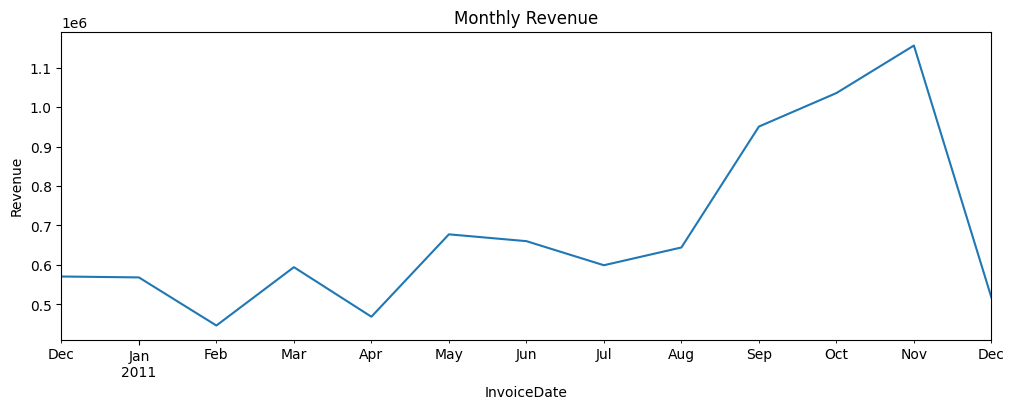

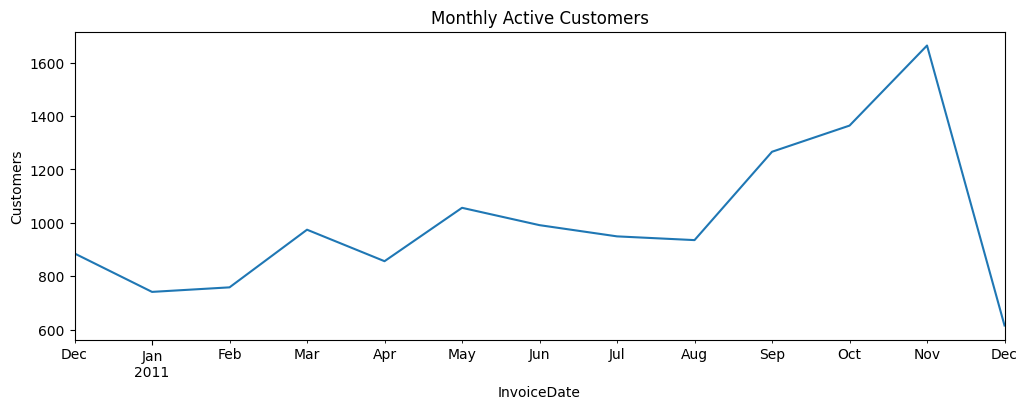

In [7]:
# 4. Data sanity checks / EDA
display(data.describe(include="all").T)
monthly_revenue = data.set_index("InvoiceDate").resample("MS")["Revenue"].sum()
monthly_customers = data.set_index("InvoiceDate").resample("MS")["CustomerID"].nunique()

fig, ax = plt.subplots(figsize=(12, 4))
monthly_revenue.plot(ax=ax)
ax.set_title("Monthly Revenue")
ax.set_ylabel("Revenue")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
monthly_customers.plot(ax=ax)
ax.set_title("Monthly Active Customers")
ax.set_ylabel("Customers")
plt.show()


## 5. Snapshot generation

Each snapshot is created at the beginning of the following month. The feature history is strictly earlier than that cutoff. The target is purchase activity in the following month.

The adaptive window is based on the customer's historical median inter-purchase interval, computed using invoices observed before the snapshot cutoff.


In [8]:
# 5. Snapshot / feature generation
def window_from_ipi(ipi):
    # Rule-based starting point; thresholds are hypotheses, not learned from Test.
    if pd.isna(ipi):
        return 180
    if ipi <= 15:
        return 30
    if ipi <= 30:
        return 60
    if ipi <= 60:
        return 90
    if ipi <= 120:
        return 120
    return 180

def rfm_at_snapshot(hist, cutoff, customer_id, ipi):
    # hist contains only transactions before cutoff
    if hist.empty:
        return None

    last_date = hist["InvoiceDate"].max()
    recency = (cutoff - last_date).days

    inv_lifetime = hist["InvoiceNo"].nunique()
    monetary_lifetime = hist["Revenue"].sum()
    quantity_lifetime = hist["Quantity"].sum()

    result = {
        "CustomerID": customer_id,
        "snapshot": cutoff,
        "snapshot_period": cutoff.to_period("M").strftime("%Y-%m"),
        "R_lifetime": recency,
        "F_lifetime": inv_lifetime,
        "M_lifetime": monetary_lifetime,
        "Q_lifetime": quantity_lifetime,
        "IPI_median": ipi,
        "adaptive_window": window_from_ipi(ipi),
    }

    for w in WINDOWS:
        w_hist = hist[hist["InvoiceDate"] >= cutoff - pd.Timedelta(days=w)]
        result[f"F_{w}"] = w_hist["InvoiceNo"].nunique()
        result[f"M_{w}"] = w_hist["Revenue"].sum()
        result[f"Q_{w}"] = w_hist["Quantity"].sum()

    aw = result["adaptive_window"]
    aw_hist = hist[hist["InvoiceDate"] >= cutoff - pd.Timedelta(days=aw)]
    result["F_adaptive"] = aw_hist["InvoiceNo"].nunique()
    result["M_adaptive"] = aw_hist["Revenue"].sum()
    result["Q_adaptive"] = aw_hist["Quantity"].sum()

    # Recent-vs-longer-term ratios and changes
    result["F_ratio_30_90"] = result["F_30"] / (result["F_90"] + 1)
    result["M_ratio_30_90"] = result["M_30"] / (result["M_90"] + 1)
    result["F_ratio_30_180"] = result["F_30"] / (result["F_180"] + 1)
    result["M_ratio_30_180"] = result["M_30"] / (result["M_180"] + 1)
    result["F_delta_30_90"] = result["F_30"] - result["F_90"] / 3
    result["M_delta_30_90"] = result["M_30"] - result["M_90"] / 3

    return result

def build_snapshots(df, start="2010-12", end="2011-10"):
    periods = pd.period_range(start, end, freq="M")
    rows = []
    grouped = {cid: g.sort_values("InvoiceDate") for cid, g in df.groupby("CustomerID")}

    for p in periods:
        cutoff = (p + 1).start_time
        target_start = cutoff
        target_end = (p + 2).start_time

        for cid, hist_all in grouped.items():
            hist = hist_all[hist_all["InvoiceDate"] < cutoff]
            if hist.empty:
                continue

            invoice_dates = (
                hist.groupby("InvoiceNo")["InvoiceDate"].min()
                .sort_values().drop_duplicates()
            )
            ipi = invoice_dates.diff().dt.days.dropna()
            median_ipi = ipi.median() if len(ipi) else np.nan

            row = rfm_at_snapshot(hist, cutoff, cid, median_ipi)
            if row is None:
                continue

            future = hist_all[
                (hist_all["InvoiceDate"] >= target_start) &
                (hist_all["InvoiceDate"] < target_end)
            ]
            row["target_purchase_next_month"] = int(future["InvoiceNo"].nunique() > 0)
            rows.append(row)

    snapshots = pd.DataFrame(rows)
    if snapshots.empty:
        raise ValueError("No snapshots generated. Check dataset path/date range.")

    snapshots = snapshots.sort_values(["CustomerID", "snapshot"]).reset_index(drop=True)

    # Temporal features from previous snapshots only.
    for col in ["F_90", "M_90", "F_adaptive", "M_adaptive"]:
        snapshots[f"{col}_lag1"] = snapshots.groupby("CustomerID")[col].shift(1)
        snapshots[f"{col}_delta1"] = snapshots[col] - snapshots[f"{col}_lag1"]

    snapshots["F_90_lag1"] = snapshots["F_90_lag1"].fillna(0)
    snapshots["M_90_lag1"] = snapshots["M_90_lag1"].fillna(0)
    snapshots["F_adaptive_lag1"] = snapshots["F_adaptive_lag1"].fillna(0)
    snapshots["M_adaptive_lag1"] = snapshots["M_adaptive_lag1"].fillna(0)
    snapshots["F_90_delta1"] = snapshots["F_90_delta1"].fillna(0)
    snapshots["M_90_delta1"] = snapshots["M_90_delta1"].fillna(0)
    snapshots["F_adaptive_delta1"] = snapshots["F_adaptive_delta1"].fillna(0)
    snapshots["M_adaptive_delta1"] = snapshots["M_adaptive_delta1"].fillna(0)

    return snapshots

snapshots = build_snapshots(data)
print("Snapshot rows:", snapshots.shape)
display(snapshots.head())
print(snapshots.groupby("snapshot_period")["target_purchase_next_month"].agg(["count", "mean"]))


Snapshot rows: (28170, 42)


,CustomerID,snapshot,snapshot_period,R_lifetime,F_lifetime,M_lifetime,Q_lifetime,IPI_median,adaptive_window,F_30,...,M_delta_30_90,target_purchase_next_month,F_90_lag1,F_90_delta1,M_90_lag1,M_90_delta1,F_adaptive_lag1,F_adaptive_delta1,M_adaptive_lag1,M_adaptive_delta1
0,12346,2011-02-01,2011-02,13,1,77183.6,74215,NaN,180,1,...,51455.733333,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,12346,2011-03-01,2011-03,41,1,77183.6,74215,NaN,180,0,...,-25727.866667,0,1.0,0.0,77183.6,0.0,1.0,0.0,77183.6,0.0
2,12346,2011-04-01,2011-04,72,1,77183.6,74215,NaN,180,0,...,-25727.866667,0,1.0,0.0,77183.6,0.0,1.0,0.0,77183.6,0.0
3,12346,2011-05-01,2011-05,102,1,77183.6,74215,NaN,180,0,...,0.000000,0,1.0,-1.0,77183.6,-77183.6,1.0,0.0,77183.6,0.0
4,12346,2011-06-01,2011-06,133,1,77183.6,74215,NaN,180,0,...,0.000000,0,0.0,0.0,0.0,0.0,1.0,0.0,77183.6,0.0


                 count      mean
snapshot_period                 
2011-01            885  0.366102
2011-02           1302  0.290323
2011-03           1682  0.310345
2011-04           2134  0.260544
2011-05           2434  0.317173
2011-06           2718  0.275570
2011-07           2960  0.257095
2011-08           3148  0.243329
2011-09           3317  0.291528
2011-10           3616  0.278208
2011-11           3974  0.337443


In [9]:
# 6. Temporal split
def in_period_range(df, start, end):
    return df["snapshot_period"].between(start, end)

train = snapshots[in_period_range(snapshots, TRAIN_START, TRAIN_END)].copy()
valid = snapshots[in_period_range(snapshots, VALID_START, VALID_END)].copy()
test = snapshots[in_period_range(snapshots, TEST_START, TEST_END)].copy()

print("Train:", train.shape, train.snapshot_period.min(), train.snapshot_period.max())
print("Valid:", valid.shape, valid.snapshot_period.min(), valid.snapshot_period.max())
print("Test :", test.shape, test.snapshot_period.min(), test.snapshot_period.max())

for name, split in [("Train", train), ("Validation", valid), ("Test", test)]:
    print(name, split.target_purchase_next_month.value_counts(normalize=True).sort_index().to_dict())


Train: (11155, 42) 2011-01 2011-06
Valid: (6108, 42) 2011-07 2011-08
Test : (6933, 42) 2011-09 2011-10
Train {0: 0.7040788883908561, 1: 0.29592111160914386}
Validation {0: 0.75, 1: 0.25}
Test {0: 0.7154190105293524, 1: 0.28458098947064764}


In [10]:
# 7. Feature sets
STATIC_FEATURES = [
    "R_lifetime", "F_lifetime", "M_lifetime", "Q_lifetime"
]

FIXED_90_FEATURES = [
    "R_lifetime", "F_90", "M_90", "Q_90"
]

def fixed_features(window):
    return ["R_lifetime", f"F_{window}", f"M_{window}", f"Q_{window}"]

ADAPTIVE_FEATURES = [
    "R_lifetime", "F_adaptive", "M_adaptive", "Q_adaptive",
    "IPI_median", "adaptive_window"
]

MULTISCALE_FEATURES = (
    ["R_lifetime", "IPI_median"] +
    [f"{m}_{w}" for w in WINDOWS for m in ["F", "M", "Q"]]
)

TEMPORAL_FEATURES = [
    "F_90_lag1", "M_90_lag1", "F_90_delta1", "M_90_delta1",
    "F_adaptive_lag1", "M_adaptive_lag1",
    "F_adaptive_delta1", "M_adaptive_delta1"
]

ADAPTIVE_TEMPORAL_FEATURES = ADAPTIVE_FEATURES + TEMPORAL_FEATURES
MULTISCALE_TEMPORAL_FEATURES = MULTISCALE_FEATURES + TEMPORAL_FEATURES

FEATURE_SETS = {
    "Static Lifetime RFM": STATIC_FEATURES,
    "Fixed Rolling 90d": FIXED_90_FEATURES,
    "Adaptive Customer-Level": ADAPTIVE_FEATURES,
    "Multi-Scale RFM": MULTISCALE_FEATURES,
    "Adaptive + Temporal": ADAPTIVE_TEMPORAL_FEATURES,
    "Multi-Scale + Temporal": MULTISCALE_TEMPORAL_FEATURES,
}


In [11]:
# 8. Model definitions and evaluation helpers
def make_rf():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

def make_lr():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])

def safe_auc(y, p):
    try:
        return roc_auc_score(y, p)
    except Exception:
        return np.nan

def metrics_at_threshold(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "ROC_AUC": safe_auc(y, p),
        "PR_AUC": average_precision_score(y, p) if len(np.unique(y)) > 1 else np.nan,
        "Threshold": threshold
    }

def best_threshold(y, p):
    thresholds = np.linspace(0.10, 0.90, 81)
    scores = [f1_score(y, (p >= t).astype(int), zero_division=0) for t in thresholds]
    return float(thresholds[int(np.argmax(scores))])

def fit_validate_test(name, features, model_factory=make_rf):
    Xtr, ytr = train[features], train["target_purchase_next_month"]
    Xva, yva = valid[features], valid["target_purchase_next_month"]
    Xte, yte = test[features], test["target_purchase_next_month"]

    model = model_factory()
    model.fit(Xtr, ytr)
    pva = model.predict_proba(Xva)[:, 1]
    threshold = best_threshold(yva, pva)

    # Refit on Train + Validation after selection, then evaluate once on Test.
    trva = pd.concat([train, valid], ignore_index=True)
    final_model = model_factory()
    final_model.fit(trva[features], trva["target_purchase_next_month"])

    ptest = final_model.predict_proba(Xte)[:, 1]
    result = metrics_at_threshold(yte, ptest, threshold)
    result["Experiment"] = name
    result["Validation_Threshold"] = threshold

    return result, final_model, ptest



In [12]:
# 9. Fixed-window selection on Validation only
window_validation = []

for w in WINDOWS:
    feats = fixed_features(w)
    model = make_rf()
    model.fit(train[feats], train["target_purchase_next_month"])
    p = model.predict_proba(valid[feats])[:, 1]
    threshold = best_threshold(valid["target_purchase_next_month"], p)
    m = metrics_at_threshold(valid["target_purchase_next_month"], p, threshold)
    m["Window"] = w
    window_validation.append(m)

window_validation = pd.DataFrame(window_validation).sort_values("F1", ascending=False)
display(window_validation)

BEST_FIXED_WINDOW = int(window_validation.iloc[0]["Window"])
print("Best fixed window selected on Validation:", BEST_FIXED_WINDOW)


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold,Window
4,0.729862,0.467717,0.583497,0.519231,0.732134,0.544695,0.44,180
3,0.680255,0.407712,0.616241,0.490743,0.713819,0.526367,0.34,120
2,0.724460,0.452264,0.483955,0.467574,0.695472,0.502039,0.43,90
1,0.644565,0.363905,0.563851,0.442332,0.674746,0.475220,0.37,60
0,0.440242,0.290985,0.862475,0.435156,0.649466,0.412387,0.21,30


Best fixed window selected on Validation: 180


In [13]:
# 10. Experiment comparison — same Random Forest model
experiments = {
    "Static Lifetime RFM": STATIC_FEATURES,
    "Fixed Rolling 90d": FIXED_90_FEATURES,
    f"Best Fixed Rolling {BEST_FIXED_WINDOW}d": fixed_features(BEST_FIXED_WINDOW),
    "Customer-Level Adaptive": ADAPTIVE_FEATURES,
    "Multi-Scale RFM": MULTISCALE_FEATURES,
    "Adaptive + Temporal": ADAPTIVE_TEMPORAL_FEATURES,
    "Multi-Scale + Temporal": MULTISCALE_TEMPORAL_FEATURES,
}

results = []
trained_models = {}
test_probabilities = {}

for name, feats in experiments.items():
    res, model, ptest = fit_validate_test(name, feats, make_rf)
    results.append(res)
    trained_models[name] = model
    test_probabilities[name] = ptest

comparison = pd.DataFrame(results).sort_values(["F1", "PR_AUC"], ascending=False)
display(comparison)


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold,Experiment,Validation_Threshold
5,0.710082,0.491471,0.540294,0.514727,0.712057,0.555843,0.38,Adaptive + Temporal,0.38
6,0.729410,0.527510,0.471363,0.497859,0.711338,0.557748,0.42,Multi-Scale + Temporal,0.42
4,0.720612,0.509688,0.479980,0.494388,0.705639,0.553873,0.41,Multi-Scale RFM,0.41
2,0.720612,0.509804,0.474404,0.491468,0.700431,0.535013,0.44,Best Fixed Rolling 180d,0.44
3,0.685850,0.455064,0.526102,0.488011,0.691552,0.505613,0.37,Customer-Level Adaptive,0.37
0,0.714698,0.498641,0.464774,0.481112,0.703139,0.541523,0.48,Static Lifetime RFM,0.48
1,0.712823,0.494368,0.400405,0.442453,0.672731,0.508824,0.43,Fixed Rolling 90d,0.43


In [14]:
# 11. Additional Logistic Regression baselines
lr_experiments = {
    "LR Static RFM": STATIC_FEATURES,
    "LR Adaptive + Temporal": ADAPTIVE_TEMPORAL_FEATURES
}

lr_results = []
for name, feats in lr_experiments.items():
    res, model, ptest = fit_validate_test(name, feats, make_lr)
    lr_results.append(res)
    trained_models[name] = model
    test_probabilities[name] = ptest

lr_comparison = pd.DataFrame(lr_results)
display(lr_comparison)


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold,Experiment,Validation_Threshold
0,0.694937,0.471091,0.586417,0.522466,0.725708,0.565380,0.52,LR Static RFM,0.52
1,0.671715,0.446219,0.637101,0.524843,0.720253,0.556055,0.41,LR Adaptive + Temporal,0.41


In [15]:
# 12. Majority-class baseline
majority_class = int(train["target_purchase_next_month"].mode()[0])
y_test = test["target_purchase_next_month"].values
p_majority = np.full(len(test), majority_class, dtype=float)

majority_result = metrics_at_threshold(y_test, p_majority, threshold=0.5)
majority_result["Experiment"] = "Majority Class"
display(pd.DataFrame([majority_result]))


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold,Experiment
0,0.715419,0.0,0.0,0.0,0.5,0.284581,0.5,Majority Class


In [16]:
# 13. Per-snapshot Test performance
best_names = list(experiments.keys())
snapshot_results = []

for name in best_names:
    p = test_probabilities[name]
    tmp = test[["snapshot_period", "target_purchase_next_month"]].copy()
    tmp["probability"] = p
    threshold = comparison.loc[comparison.Experiment == name, "Validation_Threshold"].iloc[0]
    tmp["prediction"] = (tmp["probability"] >= threshold).astype(int)

    for period, g in tmp.groupby("snapshot_period"):
        snapshot_results.append({
            "Experiment": name,
            "Snapshot": period,
            "F1": f1_score(g.target_purchase_next_month, g.prediction, zero_division=0),
            "Precision": precision_score(g.target_purchase_next_month, g.prediction, zero_division=0),
            "Recall": recall_score(g.target_purchase_next_month, g.prediction, zero_division=0),
            "PR_AUC": average_precision_score(g.target_purchase_next_month, g.probability)
                if g.target_purchase_next_month.nunique() > 1 else np.nan
        })

snapshot_comparison = pd.DataFrame(snapshot_results)
display(snapshot_comparison)


,Experiment,Snapshot,F1,Precision,Recall,PR_AUC
0,Static Lifetime RFM,2011-09,0.493565,0.537805,0.456050,0.567953
1,Static Lifetime RFM,2011-10,0.470123,0.467125,0.473161,0.520446
2,Fixed Rolling 90d,2011-09,0.461272,0.522936,0.412616,0.534443
3,Fixed Rolling 90d,2011-10,0.424769,0.468263,0.388668,0.487042
4,Best Fixed Rolling 180d,2011-09,0.502188,0.533101,0.474664,0.559785
5,Best Fixed Rolling 180d,2011-10,0.481575,0.489231,0.474155,0.513453
6,Customer-Level Adaptive,2011-09,0.505634,0.480447,0.533609,0.516641
7,Customer-Level Adaptive,2011-10,0.471758,0.432477,0.518887,0.495486
8,Multi-Scale RFM,2011-09,0.501618,0.524239,0.480869,0.572442
9,Multi-Scale RFM,2011-10,0.487607,0.496395,0.479125,0.537046


Best experiment: Adaptive + Temporal
Threshold: 0.38
[[3857 1103]
 [ 907 1066]]


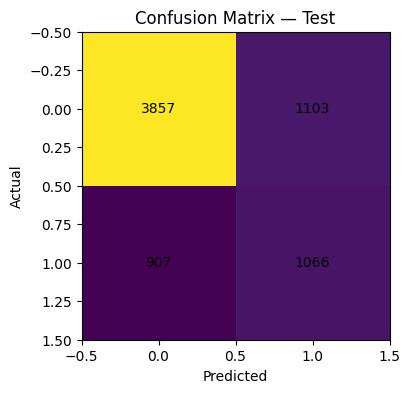

In [17]:
# 14. Confusion matrix for the best F1 experiment
best_experiment = comparison.iloc[0]["Experiment"]
best_threshold_value = comparison.iloc[0]["Validation_Threshold"]
best_probs = test_probabilities[best_experiment]
best_preds = (best_probs >= best_threshold_value).astype(int)

cm = confusion_matrix(test["target_purchase_next_month"], best_preds)
print("Best experiment:", best_experiment)
print("Threshold:", best_threshold_value)
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm)
ax.set_title("Confusion Matrix — Test")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
for (i, j), val in np.ndenumerate(cm):
    ax.text(j, i, str(val), ha="center", va="center")
plt.show()


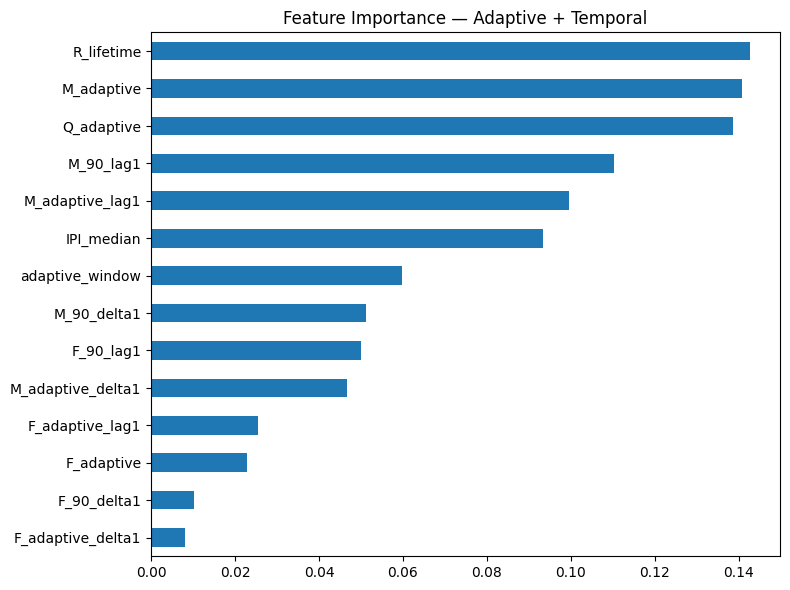

,0
R_lifetime,0.142718
M_adaptive,0.140904
Q_adaptive,0.138733
M_90_lag1,0.110292
M_adaptive_lag1,0.099593
IPI_median,0.093447
adaptive_window,0.059863
M_90_delta1,0.051201
F_90_lag1,0.050110
M_adaptive_delta1,0.046728


In [18]:
# 15. Feature importance (Random Forest)
def plot_feature_importance(model, feature_names, title):
    rf = model.named_steps["model"]
    imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values().tail(20)
    ax = imp.plot(kind="barh", figsize=(8, 6))
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return imp.sort_values(ascending=False)

if best_experiment in experiments:
    best_features = experiments[best_experiment]
    display(plot_feature_importance(
        trained_models[best_experiment],
        best_features,
        f"Feature Importance — {best_experiment}"
    ))


In [19]:
# 16. Cluster-aware bootstrap CI for F1 difference
# Resample CustomerIDs, preserving all snapshots belonging to sampled customers.
def customer_bootstrap_f1_difference(
    y_true, pred_a, pred_b, customer_ids, n_boot=1000, random_state=42
):
    rng = np.random.default_rng(random_state)
    customer_ids = np.asarray(customer_ids)
    unique_ids = np.unique(customer_ids)
    diffs = []

    id_to_idx = {cid: np.where(customer_ids == cid)[0] for cid in unique_ids}

    for _ in range(n_boot):
        sampled_ids = rng.choice(unique_ids, size=len(unique_ids), replace=True)
        idx = np.concatenate([id_to_idx[cid] for cid in sampled_ids])
        f1_a = f1_score(y_true[idx], pred_a[idx], zero_division=0)
        f1_b = f1_score(y_true[idx], pred_b[idx], zero_division=0)
        diffs.append(f1_a - f1_b)

    diffs = np.asarray(diffs)
    return {
        "mean_difference": float(np.mean(diffs)),
        "ci_lower": float(np.quantile(diffs, 0.025)),
        "ci_upper": float(np.quantile(diffs, 0.975)),
        "probability_adaptive_better": float(np.mean(diffs > 0))
    }

# Compare Adaptive + Temporal against the Best Fixed Rolling Window.
adaptive_name = "Adaptive + Temporal"
best_fixed_name = f"Best Fixed Rolling {BEST_FIXED_WINDOW}d"

if adaptive_name in test_probabilities and best_fixed_name in test_probabilities:
    threshold_adaptive = comparison.loc[
        comparison.Experiment == adaptive_name, "Validation_Threshold"
    ].iloc[0]
    threshold_fixed = comparison.loc[
        comparison.Experiment == best_fixed_name, "Validation_Threshold"
    ].iloc[0]

    pred_adaptive = (test_probabilities[adaptive_name] >= threshold_adaptive).astype(int)
    pred_fixed = (test_probabilities[best_fixed_name] >= threshold_fixed).astype(int)

    bootstrap_result = customer_bootstrap_f1_difference(
        test["target_purchase_next_month"].values,
        pred_adaptive,
        pred_fixed,
        test["CustomerID"].values,
        n_boot=1000
    )
    display(pd.DataFrame([bootstrap_result]))
else:
    print("Adaptive/Best-Fixed comparison not available.")


,mean_difference,ci_lower,ci_upper,probability_adaptive_better
0,0.022944,0.006341,0.03853,0.998


In [20]:
# 17. Ablation study — test the contribution of feature groups
ablation_features = {
    "Adaptive RFM only": ADAPTIVE_FEATURES,
    "Adaptive RFM + IPI": ADAPTIVE_FEATURES,
    "Adaptive RFM + Temporal": ADAPTIVE_TEMPORAL_FEATURES,
    "Multi-Scale RFM only": MULTISCALE_FEATURES,
    "Multi-Scale + Temporal": MULTISCALE_TEMPORAL_FEATURES,
}

ablation_results = []
for name, feats in ablation_features.items():
    res, _, _ = fit_validate_test(name, feats, make_rf)
    ablation_results.append(res)

ablation = pd.DataFrame(ablation_results).sort_values("F1", ascending=False)
display(ablation)


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold,Experiment,Validation_Threshold
2,0.710082,0.491471,0.540294,0.514727,0.712057,0.555843,0.38,Adaptive RFM + Temporal,0.38
4,0.729410,0.527510,0.471363,0.497859,0.711338,0.557748,0.42,Multi-Scale + Temporal,0.42
3,0.720612,0.509688,0.479980,0.494388,0.705639,0.553873,0.41,Multi-Scale RFM only,0.41
0,0.685850,0.455064,0.526102,0.488011,0.691552,0.505613,0.37,Adaptive RFM only,0.37
1,0.685850,0.455064,0.526102,0.488011,0.691552,0.505613,0.37,Adaptive RFM + IPI,0.37


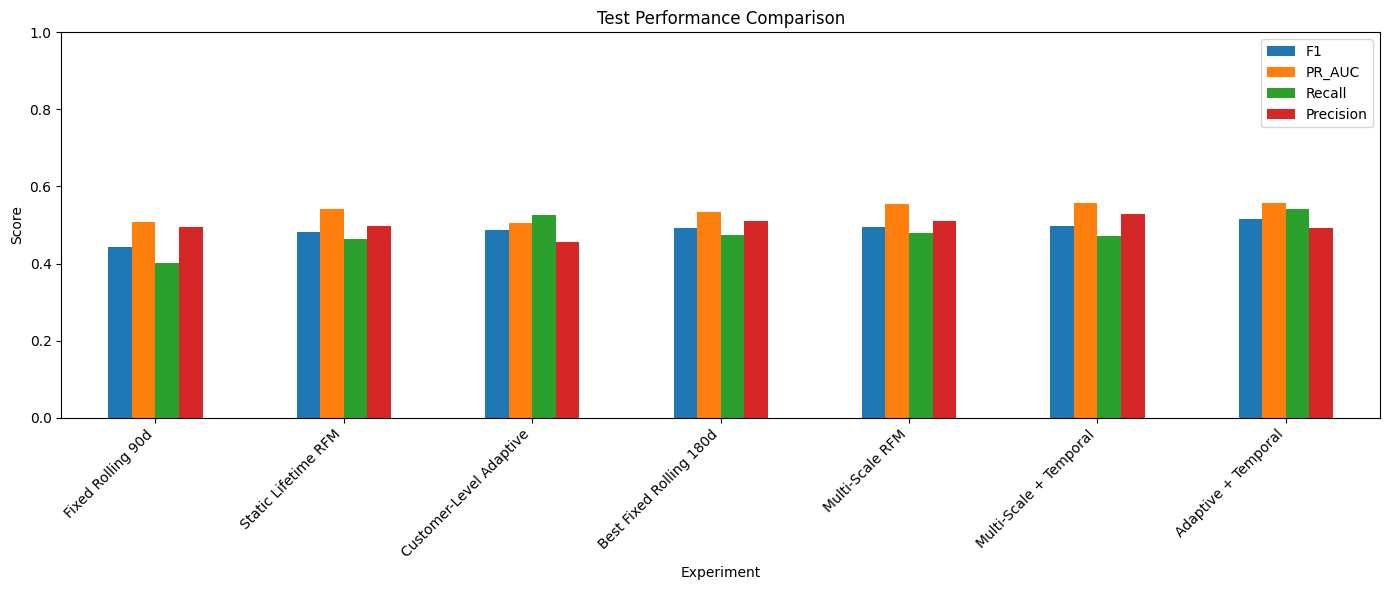

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold,Experiment,Validation_Threshold
5,0.710082,0.491471,0.540294,0.514727,0.712057,0.555843,0.38,Adaptive + Temporal,0.38
6,0.729410,0.527510,0.471363,0.497859,0.711338,0.557748,0.42,Multi-Scale + Temporal,0.42
4,0.720612,0.509688,0.479980,0.494388,0.705639,0.553873,0.41,Multi-Scale RFM,0.41
2,0.720612,0.509804,0.474404,0.491468,0.700431,0.535013,0.44,Best Fixed Rolling 180d,0.44
3,0.685850,0.455064,0.526102,0.488011,0.691552,0.505613,0.37,Customer-Level Adaptive,0.37
0,0.714698,0.498641,0.464774,0.481112,0.703139,0.541523,0.48,Static Lifetime RFM,0.48
1,0.712823,0.494368,0.400405,0.442453,0.672731,0.508824,0.43,Fixed Rolling 90d,0.43


In [21]:
# 18. Summary plots
plot_metrics = ["F1", "PR_AUC", "Recall", "Precision"]
plot_df = comparison.set_index("Experiment")[plot_metrics].sort_values("F1")

ax = plot_df.plot(kind="bar", figsize=(14, 6))
ax.set_title("Test Performance Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(comparison.sort_values("F1", ascending=False))


## 19. Research interpretation template

Do not claim Adaptive RFM is superior unless the Test results support it.

Report:
1. Adaptive vs Static RFM.
2. Adaptive vs Fixed 90-day RFM.
3. Adaptive vs Best Fixed Window selected on Validation.
4. Per-snapshot performance.
5. PR-AUC and Recall, not Accuracy alone.
6. Bootstrap confidence interval of F1 difference.
7. Ablation: contribution of Adaptive Window, Multi-Scale features, and Temporal features.

### Limitations
- Online Retail I spans approximately one year, limiting the number of independent temporal folds.
- Rule-based customer-level window thresholds are initial hypotheses. They should be validated using historical data only.
- Snapshot rows for the same customer are dependent; customer-level bootstrap is used for uncertainty estimation.
- A better score does not automatically prove business value. Consider expected campaign cost and customer value in future work.
